# **Exercise 5 · Women vs men (ANSUR II)**

### **Imports &Setup**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'FreeSerif', 'DejaVu Serif'],
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
})
SKY, SKY_EDGE = '#9AD0EC', '#5BA8D6'
YELLOW, YELLOW_EDGE = '#F8DC75', '#D9B93A'
GRAY = '#8A94A6'

from scipy.stats import skew
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
PASTEL = LinearSegmentedColormap.from_list('pastel', ['#FFFFFF', SKY])

### **Q5 (a) · Load the data**

In [2]:
male = pd.read_csv('ANSUR_II_MALE.csv')
female = pd.read_csv('ANSUR_II_FEMALE.csv')
for frame, label in [(male, 'Male'), (female, 'Female')]:
    frame.columns = [c.strip().lower() for c in frame.columns]
    frame['gender'] = label
print('Male:', male.shape, '| female:', female.shape)

Male: (4082, 99) | female: (1986, 99)


### **Q5 (b) · Preprocess and clean**

In [3]:
ansur = pd.concat([male, female], ignore_index=True, sort=False)

ADMIN = ['component', 'branch', 'bmi_class', 'height_class']
ansur = ansur.drop(columns=[c for c in ADMIN if c in ansur.columns])

print('Duplicate rows:', int(ansur.duplicated().sum()))
ansur = ansur.drop_duplicates().reset_index(drop=True)

numeric = ansur.drop(columns='gender').select_dtypes('number')
print('Measurement columns:', numeric.shape[1])
print('Missing values:', int(numeric.isna().sum().sum()))
print('Non-positive values:', int((numeric <= 0).sum().sum()))
print(ansur['gender'].value_counts().to_dict())

Duplicate rows: 0
Measurement columns: 94
Missing values: 0
Non-positive values: 0
{'Male': 4082, 'Female': 1986}


### **Q5 (c) · Heights of women and men**

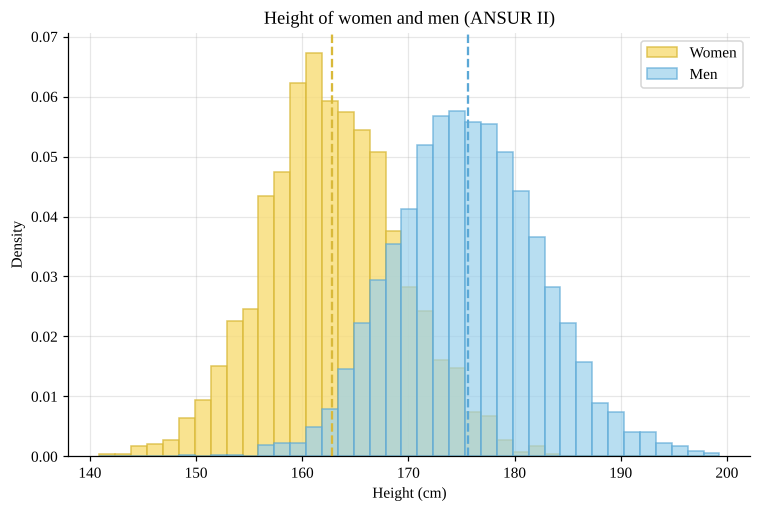

In [4]:
height = ansur.assign(height_cm=ansur['stature_m'] * 100)
women = height.loc[height['gender'] == 'Female', 'height_cm']
men = height.loc[height['gender'] == 'Male', 'height_cm']

fig, ax = plt.subplots(figsize=(8, 5))
bins = np.linspace(height['height_cm'].min(), height['height_cm'].max(), 40)
ax.hist(women, bins=bins, density=True, alpha=0.8, color=YELLOW, edgecolor=YELLOW_EDGE, label='Women')
ax.hist(men, bins=bins, density=True, alpha=0.7, color=SKY, edgecolor=SKY_EDGE, label='Men')
ax.axvline(women.mean(), color=YELLOW_EDGE, linestyle='--')
ax.axvline(men.mean(), color=SKY_EDGE, linestyle='--')
ax.set_xlabel('Height (cm)')
ax.set_ylabel('Density')
ax.set_title('Height of women and men (ANSUR II)')
ax.legend()
plt.show()

In [5]:
stats = pd.DataFrame({'women': women.describe(), 'men': men.describe()}).T[['count', 'mean', 'std', 'min', 'max']]
stats['skewness'] = [skew(women), skew(men)]
display(stats.round(2))
print('Mean difference (cm):', round(men.mean() - women.mean(), 1))

,count,mean,std,min,max,skewness
women,1986.0,162.85,6.42,140.9,182.9,0.09
men,4082.0,175.62,6.86,149.1,199.3,0.11


Mean difference (cm): 12.8


### **Q5 (d) · Train and test split (80% / 20%)**

In [6]:
X = ansur.drop(columns='gender').select_dtypes('number')
y = (ansur['gender'] == 'Male').astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Train:', X_train.shape, '| test:', X_test.shape, '| male share:', round(y_train.mean(), 3), '/', round(y_test.mean(), 3))
medians = X_train.median()
X_train, X_test = X_train.fillna(medians), X_test.fillna(medians)

Train: (4854, 94) | test: (1214, 94) | male share: 0.673 / 0.673


### **Q5 (e) · Decision tree vs bagging**

In [7]:
tree = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
bagging = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100, oob_score=True,
                            random_state=SEED, n_jobs=-1).fit(X_train, y_train)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, model in [('Decision tree', tree), ('Bagging of 100 trees', bagging)]:
    cv_acc = cross_val_score(clone(model), X_train, y_train, cv=cv)
    rows.append({'model': name, 'train accuracy': model.score(X_train, y_train),
                 'CV accuracy (train rows)': cv_acc.mean(), 'test accuracy': model.score(X_test, y_test)})
comparison = pd.DataFrame(rows).set_index('model').round(4)
display(comparison)
print('Out-of-bag accuracy of the bagged model:', round(bagging.oob_score_, 4))

,train accuracy,CV accuracy (train rows),test accuracy
model,,,
Decision tree,1.0,0.9784,0.9811
Bagging of 100 trees,1.0,0.9866,0.9876


Out-of-bag accuracy of the bagged model: 0.9883


### **Q5 (f) · Accuracy on the test set**

In [8]:
pred_tree = tree.predict(X_test)
pred_bag = bagging.predict(X_test)
print('Decision tree test accuracy:', round(accuracy_score(y_test, pred_tree), 4))
print('Bagging test accuracy:      ', round(accuracy_score(y_test, pred_bag), 4))

Decision tree test accuracy: 0.9811
Bagging test accuracy:       0.9876


### **Q5 (g) · Confusion matrices on the test set**

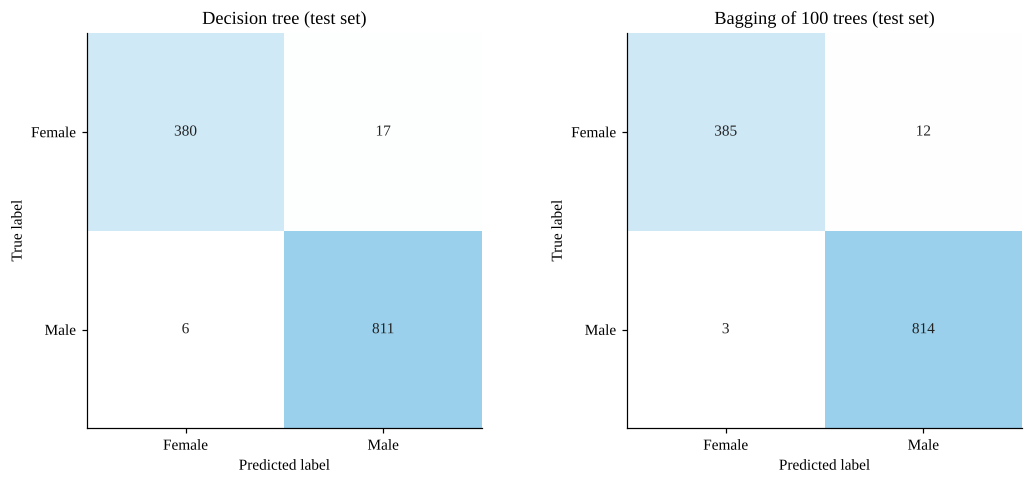

              precision    recall  f1-score   support

      Female      0.992     0.970     0.981       397
        Male      0.985     0.996     0.991       817

    accuracy                          0.988      1214
   macro avg      0.989     0.983     0.986      1214
weighted avg      0.988     0.988     0.988      1214



In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, pred, title in zip(axes, [pred_tree, pred_bag], ['Decision tree', 'Bagging of 100 trees']):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Female', 'Male']).plot(
        ax=ax, cmap=PASTEL, colorbar=False, values_format='d')
    ax.grid(False)
    for t in ax.texts:
        t.set_color('#222222')
    ax.set_title(f'{title} (test set)')
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
plt.tight_layout()
plt.show()
print(classification_report(y_test, pred_bag, target_names=['Female', 'Male'], digits=3))